# SkyPulse - AI Passenger Care System
### Machine Learning Final Review - Team 11

**Team:** Aadarsh Raj, Pranjal Jaiswal, Gaurav Singh, Ansh Singh

**Problem:** airlines find out a passenger was unhappy only after the flight. We want to predict which passengers are at risk
*during* the journey, explain why, and use that to plan recovery actions.

**Dataset:** Kaggle "Airline Passenger Satisfaction" (train + test = 129,880 rows, 22 features).

Contents: 1. Loading & pre-processing (same as Review 1) - 2. EDA - 3. Four models + tuning - 4. Comparison -
5. Booking-time model - 6. SHAP - 7. Clustering - 8. Fairness

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, silhouette_score, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RS = 42

D:\My Project files\SkyPulse\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Loading and pre-processing
We join the two Kaggle files and redo the split ourselves so we control it (stratified 80/20).

In [2]:
train_raw = pd.read_csv("data/train.csv")
test_raw = pd.read_csv("data/test.csv")
df = pd.concat([train_raw, test_raw], ignore_index=True)
print(df.shape)
df = df.drop(columns=["Unnamed: 0", "id"])
df.head()

(129880, 25)


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [3]:
df["Customer Type"] = df["Customer Type"].str.title()
df["Type of Travel"] = df["Type of Travel"].str.title()
df["Gender"] = df["Gender"].map({"Female": 0, "Male": 1})
df["Customer Type"] = df["Customer Type"].map({"Disloyal Customer": 0, "Loyal Customer": 1})
df["Type of Travel"] = df["Type of Travel"].map({"Personal Travel": 0, "Business Travel": 1})
df["Class"] = df["Class"].map({"Eco": 0, "Eco Plus": 1, "Business": 2})
df["satisfaction"] = (df["satisfaction"] == "satisfied").astype(int)

# short column names (same names the app uses)
names = ["gender", "customer_type", "age", "travel_type", "travel_class", "flight_distance", "wifi", "time_convenient",
         "online_booking", "gate_location", "food", "online_boarding", "seat_comfort", "entertainment", "onboard_service",
         "leg_room", "baggage", "checkin", "inflight_service", "cleanliness", "dep_delay", "arr_delay"]
df.columns = names + ["satisfied"]
RATINGS = names[6:20]
print(df.isna().sum()[df.isna().sum() > 0])
df["satisfied"].value_counts(normalize=True)

arr_delay    393
dtype: int64


satisfied
0    0.565537
1    0.434463
Name: proportion, dtype: float64

In [4]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["satisfied"], random_state=RS)
arr_median = train_df["arr_delay"].median()   # fit on train only, no leakage
print("train:", train_df.shape, "test:", test_df.shape, "arrival delay median:", arr_median)

def prep(d):
    X = d[names].astype(float).copy()
    X["arr_delay"] = X["arr_delay"].fillna(arr_median)
    X["dep_delay"] = np.log1p(X["dep_delay"])
    X["arr_delay"] = np.log1p(X["arr_delay"])
    return X

Xtr, Xte = prep(train_df), prep(test_df)
ytr, yte = train_df["satisfied"].values, test_df["satisfied"].values
scaler = StandardScaler().fit(Xtr)          # only for LR and SVM
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

train: (103904, 23) test: (25976, 23) arrival delay median: 0.0


## 2. Quick EDA

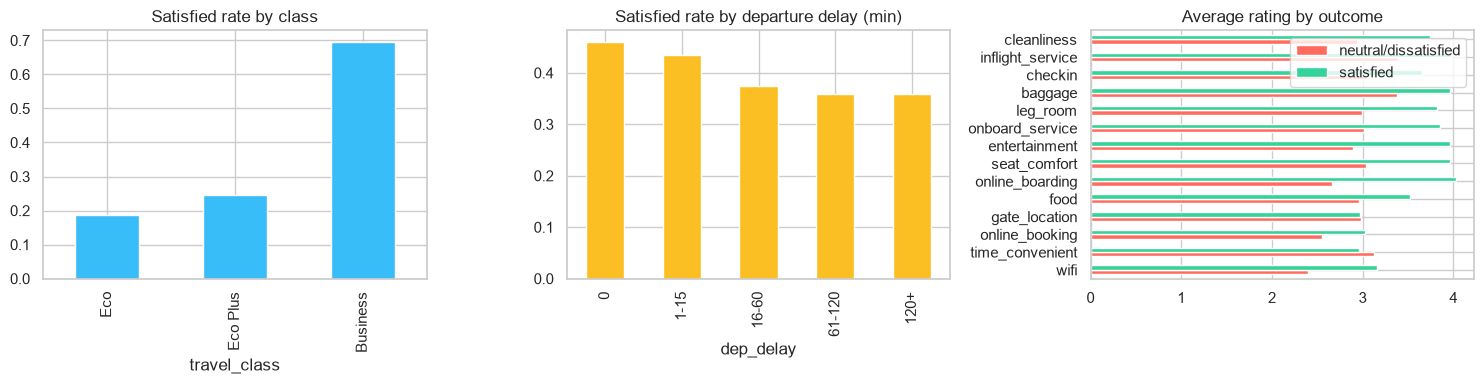

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.groupby("travel_class")["satisfied"].mean().rename({0: "Eco", 1: "Eco Plus", 2: "Business"}).plot.bar(ax=ax[0], color="#38bdf8")
ax[0].set_title("Satisfied rate by class")
pd.cut(df["dep_delay"], [-1, 0, 15, 60, 120, 10000], labels=["0", "1-15", "16-60", "61-120", "120+"]) \
  .pipe(lambda b: df.groupby(b, observed=True)["satisfied"].mean()).plot.bar(ax=ax[1], color="#fbbf24")
ax[1].set_title("Satisfied rate by departure delay (min)")
gap = df.groupby("satisfied")[RATINGS].mean().T
gap.columns = ["neutral/dissatisfied", "satisfied"]
gap.plot.barh(ax=ax[2], color=["#ff6b5e", "#34d399"])
ax[2].set_title("Average rating by outcome")
plt.tight_layout(); plt.show()

Business class and lower delays go with higher satisfaction. Online boarding and wifi show the biggest rating gap between happy and unhappy passengers.

## 3. Models with light tuning (RandomizedSearchCV, 3-fold)

In [6]:
results, models, probs = {}, {}, {}

def evaluate(name, model, X_test, fit_time, tune_time):
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probs[name] = p
    results[name] = {"accuracy": accuracy_score(yte, pred), "precision": precision_score(yte, pred),
                     "recall": recall_score(yte, pred), "f1": f1_score(yte, pred), "roc_auc": roc_auc_score(yte, p),
                     "fit_s": fit_time, "tune_s": tune_time}
    models[name] = model
    print(name, {k: round(v, 4) for k, v in results[name].items()})

In [7]:
# Logistic Regression
t = time.perf_counter()
s = RandomizedSearchCV(LogisticRegression(max_iter=2000), {"C": loguniform(1e-3, 1e2)}, n_iter=6, cv=3,
                       scoring="f1", random_state=RS, n_jobs=-1).fit(Xtr_s, ytr)
tune = time.perf_counter() - t
t = time.perf_counter()
lr = LogisticRegression(max_iter=2000, **s.best_params_).fit(Xtr_s, ytr)
evaluate("Logistic Regression", lr, Xte_s, time.perf_counter() - t, tune)
print("best params:", s.best_params_)

Logistic Regression {'accuracy': 0.8745, 'precision': 0.8704, 'recall': 0.8355, 'f1': 0.8526, 'roc_auc': 0.9283, 'fit_s': 0.0535, 'tune_s': 4.5726}
best params: {'C': np.float64(0.9846738873614566)}


RBF SVM scales badly with rows, so we tune it on 10,000 rows and train it on a 20,000-row stratified subsample.

In [8]:
Xs20, _, ys20, _ = train_test_split(Xtr_s, ytr, train_size=20000, stratify=ytr, random_state=RS)
Xs10, _, ys10, _ = train_test_split(Xs20, ys20, train_size=10000, stratify=ys20, random_state=RS)
t = time.perf_counter()
s = RandomizedSearchCV(SVC(kernel="rbf"), {"C": loguniform(0.3, 30), "gamma": loguniform(0.005, 0.2)},
                       n_iter=5, cv=3, scoring="f1", random_state=RS, n_jobs=-1).fit(Xs10, ys10)
tune = time.perf_counter() - t
t = time.perf_counter()
svm = SVC(kernel="rbf", probability=True, random_state=RS, **s.best_params_).fit(Xs20, ys20)
evaluate("SVM (RBF)", svm, Xte_s, time.perf_counter() - t, tune)
print("best params:", s.best_params_)

SVM (RBF) {'accuracy': 0.9465, 'precision': 0.9482, 'recall': 0.9274, 'f1': 0.9377, 'roc_auc': 0.9865, 'fit_s': 14.6431, 'tune_s': 2.979}
best params: {'C': np.float64(8.731907739399205), 'gamma': np.float64(0.045504758132021865)}


In [9]:
# Random Forest - search on a 30k subsample, final fit on the full training set
Xr30, _, yr30, _ = train_test_split(Xtr, ytr, train_size=30000, stratify=ytr, random_state=RS)
t = time.perf_counter()
s = RandomizedSearchCV(RandomForestClassifier(random_state=RS, n_jobs=-1),
                       {"n_estimators": randint(150, 400), "max_depth": [None, 20, 30],
                        "min_samples_leaf": randint(1, 4), "max_features": ["sqrt", 0.5]},
                       n_iter=6, cv=3, scoring="f1", random_state=RS).fit(Xr30, yr30)
tune = time.perf_counter() - t
t = time.perf_counter()
rf = RandomForestClassifier(random_state=RS, n_jobs=-1, **s.best_params_).fit(Xtr, ytr)
evaluate("Random Forest", rf, Xte, time.perf_counter() - t, tune)
print("best params:", s.best_params_)

Random Forest {'accuracy': 0.9637, 'precision': 0.9728, 'recall': 0.9428, 'f1': 0.9576, 'roc_auc': 0.9947, 'fit_s': 3.2802, 'tune_s': 14.8671}
best params: {'max_depth': 30, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 170}


For XGBoost we add a monotonic constraint on the two delay columns: a longer delay should never make the model *more* confident a passenger is happy.

In [10]:
MONO = tuple(-1 if c in ("dep_delay", "arr_delay") else 0 for c in names)
t = time.perf_counter()
s = RandomizedSearchCV(XGBClassifier(tree_method="hist", random_state=RS, n_jobs=-1, eval_metric="logloss", monotone_constraints=MONO),
                       {"n_estimators": randint(300, 700), "max_depth": randint(5, 10), "learning_rate": uniform(0.03, 0.12),
                        "subsample": uniform(0.7, 0.3), "colsample_bytree": uniform(0.6, 0.4)},
                       n_iter=8, cv=3, scoring="f1", random_state=RS).fit(Xtr, ytr)
tune = time.perf_counter() - t
t = time.perf_counter()
xgb = XGBClassifier(tree_method="hist", random_state=RS, n_jobs=-1, eval_metric="logloss", monotone_constraints=MONO,
                    **s.best_params_).fit(Xtr, ytr)
evaluate("XGBoost", xgb, Xte, time.perf_counter() - t, tune)
print("best params:", s.best_params_)

XGBoost {'accuracy': 0.9634, 'precision': 0.9725, 'recall': 0.9423, 'f1': 0.9572, 'roc_auc': 0.9954, 'fit_s': 1.1021, 'tune_s': 29.7626}
best params: {'colsample_bytree': np.float64(0.6624074561769746), 'learning_rate': np.float64(0.048719342440344315), 'max_depth': 7, 'n_estimators': 387, 'subsample': np.float64(0.8001125833417065)}


## 4. Comparison

In [11]:
table = pd.DataFrame(results).T.round(4)
table.sort_values("f1", ascending=False)

,accuracy,precision,recall,f1,roc_auc,fit_s,tune_s
Random Forest,0.9637,0.9728,0.9428,0.9576,0.9947,3.2802,14.8671
XGBoost,0.9634,0.9725,0.9423,0.9572,0.9954,1.1021,29.7626
SVM (RBF),0.9465,0.9482,0.9274,0.9377,0.9865,14.6431,2.9790
Logistic Regression,0.8745,0.8704,0.8355,0.8526,0.9283,0.0535,4.5726


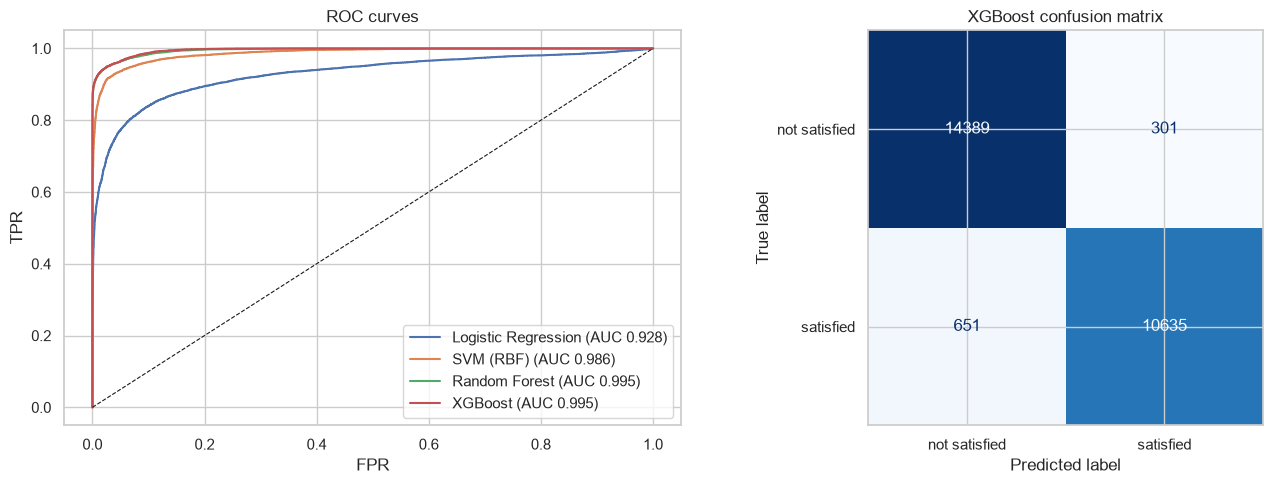

Best by F1: Random Forest


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(yte, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {results[name]['roc_auc']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend(); ax[0].set_title("ROC curves")
ConfusionMatrixDisplay(confusion_matrix(yte, (probs["XGBoost"] >= 0.5).astype(int)),
                       display_labels=["not satisfied", "satisfied"]).plot(ax=ax[1], colorbar=False, cmap="Blues")
ax[1].set_title("XGBoost confusion matrix"); plt.tight_layout(); plt.show()
print("Best by F1:", table["f1"].idxmax())

Random Forest and XGBoost are almost tied (difference in F1 is under 0.1 percentage point). In the app we serve XGBoost because
the delay constraint makes its behaviour sensible during live events, it is faster, and SHAP values for it are exact and quick.

## 5. Booking-time model
Can we predict satisfaction before the trip, using only what we know at booking?

In [13]:
BOOKING = ["gender", "customer_type", "age", "travel_type", "travel_class", "flight_distance"]
bk = XGBClassifier(tree_method="hist", random_state=RS, n_jobs=-1, eval_metric="logloss",
                   n_estimators=400, max_depth=6, learning_rate=0.05).fit(train_df[BOOKING], ytr)
pb = bk.predict_proba(test_df[BOOKING])[:, 1]
print("booking-time accuracy:", round(accuracy_score(yte, pb >= 0.5), 4), " F1:", round(f1_score(yte, pb >= 0.5), 4),
      " ROC-AUC:", round(roc_auc_score(yte, pb), 4))
print("full XGBoost accuracy:", round(results["XGBoost"]["accuracy"], 4))

booking-time accuracy: 0.8  F1: 0.7687  ROC-AUC: 0.8612
full XGBoost accuracy: 0.9634


The booking-time model is clearly weaker. Most of the signal is in the in-flight experience, which is why SkyPulse scores passengers during the journey.

## 6. Explaining predictions with SHAP

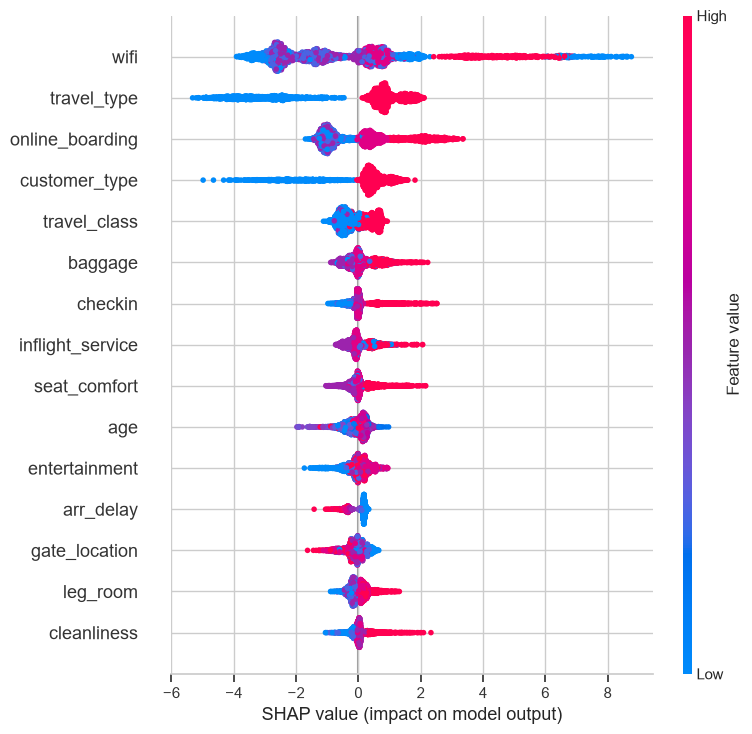

In [14]:
explainer = shap.TreeExplainer(xgb)
sample = Xte.sample(3000, random_state=RS)
sv = explainer.shap_values(sample)
shap.summary_plot(sv, sample, show=False, max_display=15)
plt.tight_layout(); plt.show()

In [15]:
imp = pd.Series(np.abs(sv).mean(axis=0), index=names).sort_values(ascending=False)
imp.head(10).round(4)

wifi                2.0556
travel_type         1.6719
online_boarding     0.9960
customer_type       0.8036
travel_class        0.4151
baggage             0.3626
checkin             0.3055
inflight_service    0.2858
seat_comfort        0.2756
age                 0.2619
dtype: float32

In [16]:
# one unhappy passenger from the test set
i = np.where(probs["XGBoost"] < 0.1)[0][0]
row = Xte.iloc[[i]]
one = pd.Series(explainer.shap_values(row)[0], index=names).sort_values(key=abs, ascending=False)
print("P(satisfied) =", round(probs["XGBoost"][i], 3))
one.head(6).round(3)

P(satisfied) = 0.003


travel_type       -4.398
wifi              -2.624
online_boarding    1.167
baggage            0.542
travel_class      -0.492
online_booking     0.359
dtype: float32

Negative SHAP values push towards 'not satisfied'. These top reasons are what the app turns into plain-English explanations and recovery actions.

## 7. Passenger segments (K-Means)

In [17]:
sil_idx = np.random.RandomState(RS).choice(len(Xtr_s), 10000, replace=False)
sil = {}
for k in (4, 5, 6):
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(Xtr_s)
    sil[k] = silhouette_score(Xtr_s[sil_idx], km.labels_[sil_idx])
    print(k, round(sil[k], 4))
k_best = max(sil, key=sil.get)
km = KMeans(n_clusters=k_best, n_init=10, random_state=RS).fit(Xtr_s)
print("chosen k =", k_best)

4 0.0973


5 0.1032


6 0.1115


chosen k = 6


In [18]:
prof = train_df.assign(segment=km.labels_).groupby("segment").agg(
    size=("satisfied", "size"), satisfied=("satisfied", "mean"), age=("age", "mean"), distance=("flight_distance", "mean"),
    business_class=("travel_class", lambda s: (s == 2).mean()), business_trip=("travel_type", "mean"),
    loyal=("customer_type", "mean"))
prof.round(2)

,size,satisfied,age,distance,business_class,business_trip,loyal
segment,,,,,,,
0,18954,0.94,44.17,1847.15,0.93,1.00,1.00
1,20542,0.15,32.55,847.14,0.23,0.56,0.68
2,17826,0.11,37.65,754.02,0.05,0.03,1.00
3,17652,0.26,46.78,1230.86,0.48,0.71,0.99
4,11170,0.20,29.53,687.87,0.34,1.00,0.01
5,17760,0.88,42.93,1602.88,0.80,0.97,0.93


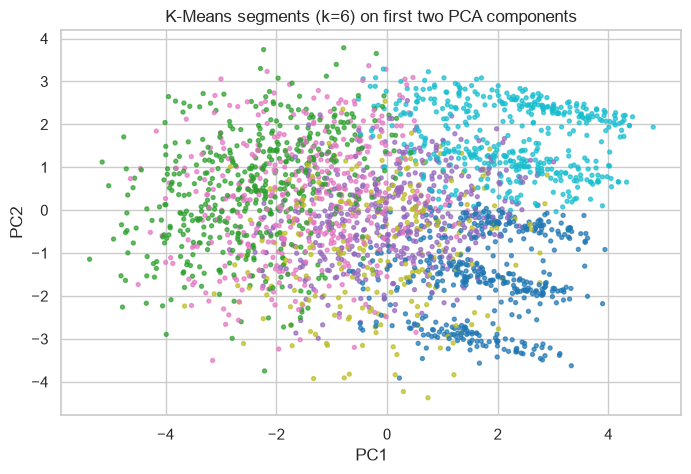

In [19]:
pca = PCA(n_components=2, random_state=RS).fit(Xtr_s)
idx = np.random.RandomState(RS).choice(len(Xtr_s), 2500, replace=False)
pts = pca.transform(Xtr_s[idx])
plt.figure(figsize=(8, 5))
plt.scatter(pts[:, 0], pts[:, 1], c=km.labels_[idx], cmap="tab10", s=8, alpha=0.7)
plt.title(f"K-Means segments (k={k_best}) on first two PCA components"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

Two segments are mostly happy long-haul Business travellers; the other four are unhappy groups, each with a different weakest service. The app names each segment from this profile table.

## 8. Fairness check

In [20]:
pred = (probs["XGBoost"] >= 0.5).astype(int)
groups = {"Gender": test_df["gender"].map({0: "Female", 1: "Male"}).values,
          "Age group": pd.cut(test_df["age"], [0, 24, 39, 59, 200], labels=["<25", "25-40", "40-60", "60+"]).astype(str).values}
rows = []
for attr, g in groups.items():
    for val in pd.unique(g):
        m = g == val
        rows.append([attr, val, m.sum(), accuracy_score(yte[m], pred[m]), f1_score(yte[m], pred[m]), yte[m].mean()])
pd.DataFrame(rows, columns=["attribute", "group", "n", "accuracy", "f1", "satisfied_rate"]).round(4)

,attribute,group,n,accuracy,f1,satisfied_rate
0,Gender,Male,12819,0.9632,0.9576,0.4408
1,Gender,Female,13157,0.9635,0.9567,0.4284
2,Age group,40-60,10863,0.9658,0.9699,0.5753
3,Age group,<25,4872,0.9565,0.9201,0.2777
4,Age group,25-40,7815,0.9646,0.9535,0.3869
5,Age group,60+,2426,0.9621,0.9279,0.2721


Accuracy is almost the same for men and women and across age groups (gap under 1 percentage point). F1 is a bit lower for
under-25 and 60+ passengers, who also have a much lower satisfied rate, so there are fewer positive examples to get right.

## Summary
- Best model by F1: Random Forest, with XGBoost practically tied; XGBoost is used in the app.
- In-flight service ratings (wifi, online boarding) and travel type drive satisfaction the most.
- A booking-time model is much weaker, so predicting *during* the journey is what makes recovery possible.
- Six passenger segments give the airline target groups for service improvements.